| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_5_Metodos_adaptativos.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_7_Stability.ipynb) |

# 7.6 Métodos implícitos: estabilidad a cambio de resolver ecuaciones

En sistemas rígidos, un método explícito puede necesitar pasos extremadamente pequeños para no divergir. Los métodos implícitos utilizan el estado final dentro de la actualización. Derivaremos Euler hacia atrás y trapecio, resolveremos un ejemplo no lineal con Newton y compararemos RK45, Radau y BDF en una ecuación con referencia exacta.

Los experimentos son autocontenidos y rápidos en CPU. Requisitos: derivadas, integrales, ecuaciones diferenciales ordinarias y errores numéricos. Ejecuta todas las celdas en orden. La solución exacta se usa como control cuando está disponible; en otros casos se compara contra una solución de referencia más precisa.

## 1. Problema de valor inicial y notación

Un problema de valor inicial tiene forma
$$y'(t)=f(t,y(t)),\qquad y(t_0)=y_0.$$
El estado $y$ puede ser un número o un vector. La función $f$ expresa la ley física y sus unidades son unidades de estado por unidades de tiempo. Bajo continuidad en $t$ y una condición local de Lipschitz en $y$, existe una solución única local; una implementación numérica no reemplaza estos supuestos.

Usaremos una malla $t_n=t_0+nh$ y una aproximación $y_n\approx y(t_n)$. Es esencial distinguir una evaluación de pendiente $f(t_n,y_n)$ de una actualización del estado. Para enfriamiento $y'=-ky$, el coeficiente $k>0$ tiene unidades de inverso del tiempo y la solución exacta es $y_0e^{-kt}$.

Un simulador introduce error de discretización además del error del modelo. Si una red se entrena con sus trayectorias, puede aprender ambas cosas. Por ello se estudian refinamiento, estabilidad y coste antes de usar los resultados como datos científicos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar
plt.rcParams.update({"figure.figsize":(9,4), "axes.grid":True, "font.size":11})
np.set_printoptions(precision=6,suppress=True)

## 2. Euler hacia atrás

La fórmula es
$$\boxed{y_{n+1}=y_n+h f(t_{n+1},y_{n+1})}.$$
La incógnita aparece en ambos lados. Definimos $G(z)=z-y_n-hf(t_{n+1},z)$ y resolvemos $G(z)=0$. Para $y'=-ky$, la solución del paso es explícita en forma algebraica:
$$y_{n+1}=\frac{y_n}{1+kh}.$$
Esto no convierte la familia en un método explícito: la simplificación ocurre porque este problema particular es lineal. Euler hacia atrás tiene orden global uno, igual que Euler explícito, pero una estabilidad mucho más amplia.

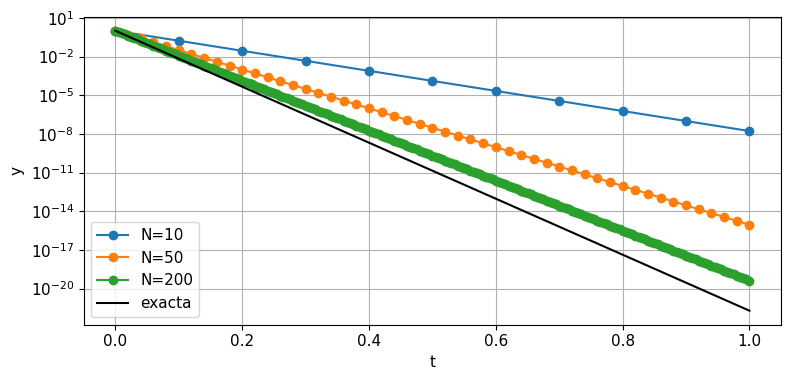

In [2]:
def backward_decay(k,tspan,y0,n):
    t=np.linspace(*tspan,n+1); h=t[1]-t[0]
    y=np.empty(n+1); y[0]=y0
    for j in range(n): y[j+1]=y[j]/(1+k*h)
    return t,y

k=50.; T=1.; q=np.linspace(0,T,500)
for n in [10,50,200]:
    t,y=backward_decay(k,(0,T),1.,n)
    plt.semilogy(t,np.maximum(y,1e-25),"o-",label=f"N={n}")
plt.semilogy(q,np.exp(-k*q),"k",label="exacta")
plt.xlabel("t"); plt.ylabel("y"); plt.legend(); plt.show()

**Interpretación.** Todos estos pasos son estables, pero los gruesos representan mal el transitorio. Estabilidad permite integrar; precisión determina si la solución responde la pregunta científica. El implícito no hace exacta una dinámica rápida no resuelta.

## 3. Estabilidad A y L

El factor de Euler hacia atrás es $R(z)=1/(1-z)$. Si $\operatorname{Re}z\le0$, $|R(z)|\le1$: es **A-estable**. Además $R(z)\to0$ cuando $z$ se aleja hacia el semiplano izquierdo: es **L-estable**, por lo que amortigua modos muy rígidos.

La estabilidad A no asegura precisión temporal ni preserva cualquier propiedad de un problema no lineal. Tampoco implica que Newton converja para cualquier tamaño de paso. Estas propiedades se analizan inicialmente en la ecuación lineal de prueba.

## 4. Trapecio implícito y oscilaciones rígidas

El trapecio implícito es
$$y_{n+1}=y_n+\frac h2[f(t_n,y_n)+f(t_{n+1},y_{n+1})].$$
Tiene orden dos y factor $R(z)=(1+z/2)/(1-z/2)$. Es A-estable pero no L-estable: para $z\to-\infty$, $R(z)\to-1$. Puede mantener oscilaciones de un modo rígido que físicamente desaparece muy rápido.

Para difusión o concentraciones, estas oscilaciones pueden ser indeseables aunque la solución no explote. Para osciladores sin amortiguación, la menor disipación puede ser valiosa. La misma propiedad se interpreta según el problema.

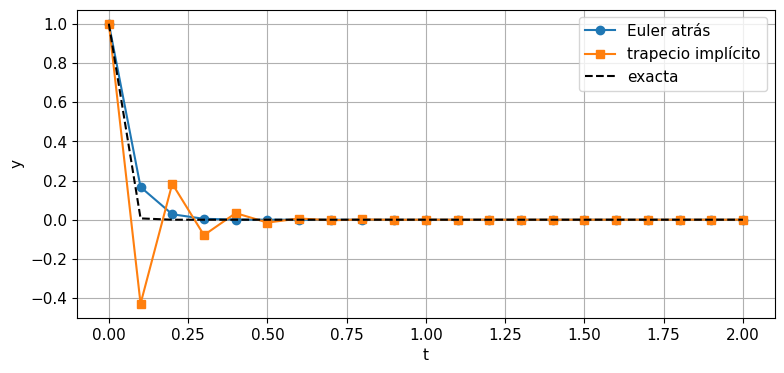

In [3]:
k=50.; h=0.1; n=20; t=np.arange(n+1)*h
back=np.empty(n+1); trap=np.empty(n+1); back[0]=trap[0]=1.
for j in range(n):
    back[j+1]=back[j]/(1+k*h)
    trap[j+1]=(1-k*h/2)/(1+k*h/2)*trap[j]
plt.plot(t,back,"o-",label="Euler atrás")
plt.plot(t,trap,"s-",label="trapecio implícito")
plt.plot(t,np.exp(-k*t),"k--",label="exacta")
plt.xlabel("t"); plt.ylabel("y"); plt.legend(); plt.show()

**Interpretación.** El trapecio produce signos alternados con $kh=5$. Euler atrás amortigua sin cambiar el signo. Ninguno representa con precisión el transitorio si se muestra solo cada $0.1$ unidades de tiempo.

## 5. Newton para un paso no lineal

En $y'=-y^3$, Euler atrás requiere resolver
$$G(z)=z-y_n+h z^3=0,\qquad G'(z)=1+3h z^2.$$
Newton actualiza $z^{(m+1)}=z^{(m)}-G(z^{(m)})/G'(z^{(m)})$. Usaremos el estado anterior como inicialización y comprobaremos el residual. La solución exacta es $y(t)=y_0/\sqrt{1+2y_0^2t}$.

El error del solver no lineal debe ser menor que el error de discretización. Iterar hasta precisión extrema en una malla muy gruesa tampoco aporta valor proporcional al coste.

Residual máximo: 9.684406054866201e-13


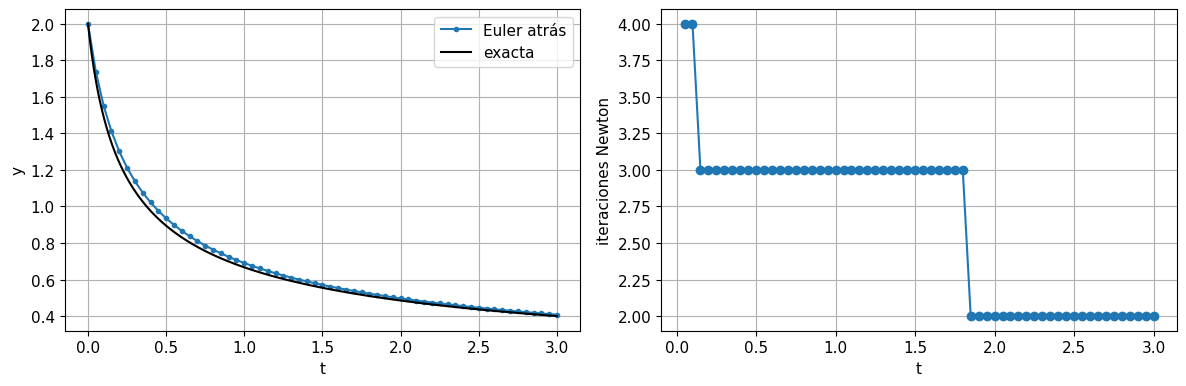

In [4]:
def backward_cubic(tspan,y0,n,tolerance=1e-12):
    t=np.linspace(*tspan,n+1); h=t[1]-t[0]
    y=np.empty(n+1); y[0]=y0; iterations=[]; residuals=[]
    for j in range(n):
        z=y[j]
        for it in range(30):
            residual=z-y[j]+h*z**3
            if abs(residual)<tolerance: break
            z -= residual/(1+3*h*z*z)
        else: raise RuntimeError("Newton no convergió")
        y[j+1]=z; iterations.append(it); residuals.append(abs(z-y[j]+h*z**3))
    return t,y,np.array(iterations),np.array(residuals)

t,y,it,res=backward_cubic((0,3),2.,60)
q=np.linspace(0,3,500)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(t,y,"o-",markersize=3,label="Euler atrás")
ax[0].plot(q,2/np.sqrt(1+8*q),"k",label="exacta"); ax[0].legend()
ax[0].set(xlabel="t",ylabel="y")
ax[1].plot(t[1:],it,"o-"); ax[1].set(xlabel="t",ylabel="iteraciones Newton")
plt.tight_layout(); plt.show()
print("Residual máximo:",res.max())

**Interpretación.** Newton converge rápidamente en este problema monotónico. Un residual pequeño certifica que se resolvió bien el paso discreto, mientras que la discrepancia con la curva exacta muestra el error temporal restante.

## 6. Una ecuación rígida con solución lenta conocida

Considera
$$y'=-k[y-\cos t]-\sin t,\qquad y(0)=1.$$
La solución exacta es $y=\cos t$ para todo $k$. Una perturbación respecto a ella decae como $e^{-kt}$: existe una escala rápida aunque la trayectoria visible sea lenta. Este es un prototipo de rigidez.

Euler atrás tiene actualización
$$y_{n+1}=\frac{y_n+h[k\cos(t_{n+1})-\sin(t_{n+1})]}{1+hk}.$$
Incluso sin resolver el modo rápido, el método puede seguir la solución lenta con precisión razonable.

Error máximo: 2.4996555198386616e-05


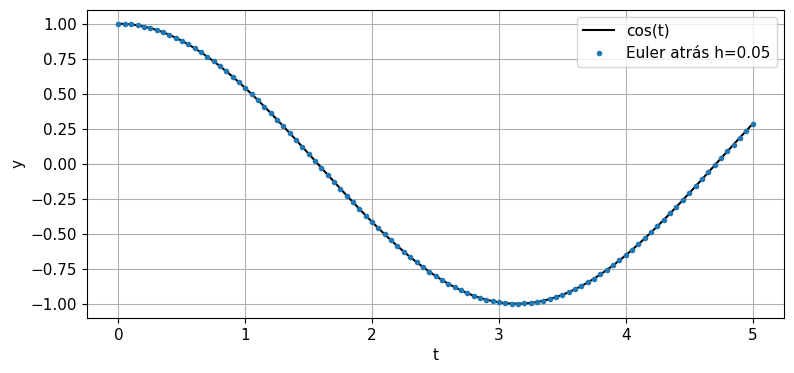

In [5]:
k=1000.; T=5.; n=100; t=np.linspace(0,T,n+1); h=T/n
y=np.empty(n+1); y[0]=1.
for j in range(n):
    y[j+1]=(y[j]+h*(k*np.cos(t[j+1])-np.sin(t[j+1])))/(1+h*k)
plt.plot(t,np.cos(t),"k",label="cos(t)")
plt.plot(t,y,"o",markersize=3,label="Euler atrás h=0.05")
plt.xlabel("t"); plt.ylabel("y"); plt.legend(); plt.show()
print("Error máximo:",np.max(abs(y-np.cos(t))))

**Interpretación.** La curva puede parecer muy precisa aunque Euler atrás sea de primer orden, porque la constante de error en esta solución particular es favorable. No debes inferir el orden general de un único ejemplo rígido con una solución especial.

## 7. RK45, Radau y BDF

SciPy ofrece métodos explícitos como RK45 y métodos para rigidez como Radau y BDF. Radau es una familia Runge–Kutta implícita; BDF usa fórmulas multistep y puede variar su orden. Proporcionar un jacobiano correcto puede reducir trabajo en sistemas grandes.

Para la ecuación escalar rígida, el jacobiano es simplemente $-k$. Comparamos número de evaluaciones y error respecto a $\cos t$ en la misma malla. El tiempo de ejecución no se usa como conclusión universal porque depende de máquina, tamaño y coste de $f$.

RK45 success True nfev 10724 nlu 0 error 6.291003139535789e-07
Radau success True nfev 151 nlu 22 error 7.916977902922007e-05
BDF success True nfev 154 nlu 19 error 5.44749878761408e-07


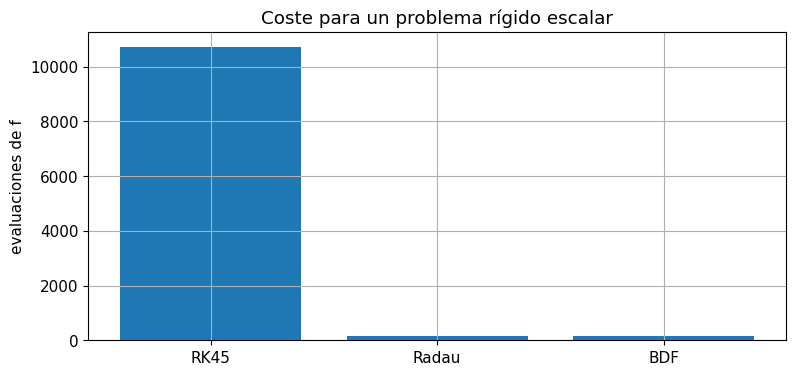

In [6]:
def stiff(t,y): return -k*(y-np.cos(t))-np.sin(t)
q=np.linspace(0,T,501); costs=[]; labels=[]
for method in ["RK45","Radau","BDF"]:
    kwargs={} if method=="RK45" else {"jac":np.array([[-k]])}
    sol=solve_ivp(stiff,(0,T),[1.],method=method,t_eval=q,
                  rtol=1e-6,atol=1e-9,**kwargs)
    labels.append(method); costs.append(sol.nfev)
    print(method,"success",sol.success,"nfev",sol.nfev,"nlu",sol.nlu,
          "error",np.max(abs(sol.y[0]-np.cos(q))))
plt.bar(labels,costs); plt.ylabel("evaluaciones de f"); plt.title("Coste para un problema rígido escalar")
plt.show()

**Interpretación.** El explícito suele consumir muchas más evaluaciones porque debe cumplir estabilidad. Los métodos implícitos añaden coste de factorizaciones y resoluciones, registrado parcialmente por `nlu`; por ello `nfev` no es la única medida de trabajo.

## 8. Orden uno y tolerancia de Newton

Para confirmar el orden de Euler atrás usamos $y'=-y$, lejos de una rigidez extrema. También puede variarse la tolerancia de Newton del ejemplo cúbico para identificar cuándo el error no lineal empieza a contaminar la convergencia temporal.

Órdenes: [0.987861 0.993956 0.996986 0.998495]


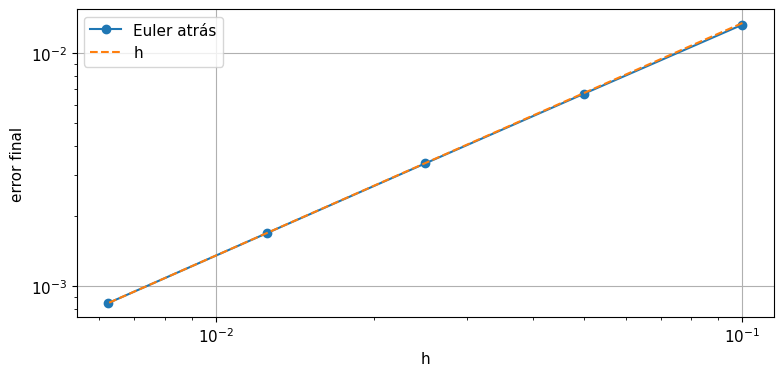

In [7]:
ns=np.array([20,40,80,160,320]); errors=[]
for n in ns:
    _,y=backward_decay(1.,(0,2),1.,n)
    errors.append(abs(y[-1]-np.exp(-2)))
errors=np.array(errors)
print("Órdenes:",np.log2(errors[:-1]/errors[1:]))
plt.loglog(2/ns,errors,"o-",label="Euler atrás")
plt.loglog(2/ns,errors[-1]*ns[-1]/ns,"--",label="h")
plt.xlabel("h"); plt.ylabel("error final"); plt.legend(); plt.show()

**Interpretación.** Estabilidad amplia no aumenta el orden: la tasa sigue siendo uno. El método explícito y el implícito pueden tener mismo orden pero constantes, sesgos y límites de paso distintos.

## 9. Sistemas, jacobianos y álgebra lineal

En un sistema, Newton resuelve
$$[I-hJ_f(t_{n+1},z^{(m)})]\Delta z=-G(z^{(m)}).$$
Se usa una resolución lineal, no una inversa explícita. En PDE discretizadas, esa matriz suele ser dispersa; aprovechar su estructura reduce memoria y coste. Factorizar una matriz y reutilizarla cuando sea válida puede ser más barato que reconstruir todo por paso.

Si Newton falla, revisa derivadas, inicialización y tamaño de paso. A-estabilidad del esquema temporal no asegura convergencia de la iteración no lineal. Algunos solvers usan Newton amortiguado, reutilización de jacobianos y criterios basados en tolerancias de integración.

## 10. Convergencia, error y coste: cómo hacer una comparación justa

Euler atrás tiene orden global $p=1$ y trapecio $p=2$. Si un método tiene orden global $p$, en el régimen asintótico se espera $E(h)\approx C h^p$ para problemas suficientemente suaves y un intervalo temporal fijo. El estimador
$$p_{\rm obs}=\log_2\frac{E(h)}{E(h/2)}$$
solo es significativo mientras el error de referencia y el redondeo sean menores que el error medido. Una trayectoria visualmente correcta puede tener error de fase, sesgo en un observable o errores localizados en transitorios.

Para comparar métodos, cuenta evaluaciones de $f$, resoluciones lineales y, en métodos implícitos, iteraciones de Newton. Un método de más orden puede ser más barato para una precisión dada, pero no necesariamente para una tolerancia muy laxa o una función no suave. Si aparecen discontinuidades o eventos, separa los intervalos suaves y localiza el cambio.

Guarda el tiempo final real de cada integración. Usar `int(T/h)` puede terminar antes de $T$ si el cociente no es entero. En estos ejemplos fijamos el número de pasos y calculamos $h=(T-t_0)/N$ para llegar exactamente al extremo. Una malla de salida fija tampoco debe confundirse con los pasos internos de un solver adaptativo.

## 11. De la simulación a SciML

En un problema inverso se ajusta un parámetro $\theta$ minimizando
$$L_h(\theta)=\sum_i\left[y_h(t_i;\theta)-y_i^{\rm obs}\right]^2.$$
El subíndice $h$ recuerda que estamos optimizando la salida de un simulador discretizado. Si el método implícito genera un sesgo sistemático, el ajuste puede compensarlo con un parámetro equivocado. Repite la inferencia con una malla más fina y observa si el parámetro estimado cambia.

En una Neural ODE, $f_\theta(t,y)$ puede ser una red, pero el solver conserva sus requisitos de regularidad y estabilidad. Reducir la pérdida de entrenamiento no prueba precisión de integración. Para física diferenciable, una derivada del programa discreto es una sensibilidad de ese programa; hace falta verificar que se estabiliza al refinar la discretización.

Define qué observable importa: valor final, energía, evento, amplitud o una norma de trayectoria. No compares únicamente la apariencia de curvas. Una evaluación científica útil separa error de datos, error de modelo y error numérico, porque mejorar uno de ellos no garantiza mejorar los demás.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_5_Metodos_adaptativos.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_7_Stability.ipynb) |